# Your own qubits: a fork transmon and the spiralmon

Two components that are not in the Quantcore library, built from scratch and used like any library cell: placed with
`Designer.add`, routed, checked by the DRC and simulated by the LOM.

| | component | what it shows |
|---|---|---|
| 1 | `ForkTransmon` (`custom_qubit.py`) | a qubit written by hand: shape from parameters, pins, a Quantcore trilayer junction across the gap, a LOM model |
| 2 | `Spiralmon` (`spiralmon.py`) | a shape someone drew (an oblique spiral): polygons + pins + a junction location become a component with `freeform.py` |

The guide pages are `docs/library/custom-components/custom-qubit.md` and `spiralmon.md`. Everything here is headless
(`QCC_LIVE=0`): the layout is built to `build/`, pictures are KLayout snapshots, the LOM is the lumped model (no FEM).

In [1]:
import os, sys
os.environ.setdefault("QCC_LIVE", "0")          # headless: build files + KLayout snapshots, no KLayout window
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)
HERE = ROOT / "examples" / "custom_component"
for p in (HERE, ROOT / "examples" / "designs"):
    sys.path.insert(0, str(p))                  # the component modules, and the notebook helpers (_common)
IMG = HERE / "img"
IMG.mkdir(exist_ok=True)

from IPython.display import Image, Markdown, display
import _common as C
from quantcore_circuits.assembly.drc import check
from quantcore_circuits.circuit.bridges import size_junction, tl_resonator
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.live.snapshot import snapshot
from quantcore_circuits.pdk import get_pdk

pdk = get_pdk()
F_Q, F_R = 5.5, 7.0                             # targets (GHz)


def snap(d, name, box=None, size=(900, 900), width=440):
    "A headless KLayout picture of the current build, saved to img/<name>.png and shown."
    if d.result is None or getattr(d, "_dirty", True):
        d.show()
    png = snapshot(d.out, IMG / f"{name}.png", size=size, box=box)
    display(Image(filename=str(png), width=width))
    return png


def drc(d):
    rep = check(d.result)
    sev = {s: sum(1 for i in rep.issues if i.severity == s) for s in ("error", "warning", "design")}
    print(f"DRC: {sev['error']} errors, {sev['warning']} warnings, {sev['design']} PDK design warnings")
    for i in rep.issues:
        print(f"  {i.severity:7s} {i.rule}: {i.message}")
    return rep


def die(name):
    "A die with two pads and a feedline FL."
    d = Designer(name, box=(0, 0, 7500, 7500), chip={"name_chip": "QC1"}, live=False)
    pw = d.add("PAD_W", "BondPad", at=(1125, 3750), rot=270, edge="auto")
    pe = d.add("PAD_E", "BondPad", at=(6375, 3750), rot=90, edge="auto")
    return d, d.route("FL", pw.a, pe.a)

# 1 · The fork transmon

`custom_qubit.py` is one Python class. It is imported from the folder (no copying into the library) and registers
itself in the KQC library, so `"custom_qubit.ForkTransmon"` works as a cell reference. The cell is a floating
two-island transmon: two forked islands (neck, body, a slot cut from the outer end) facing each other across the
junction gap, a readout claw with a tail (pin `claw`, +x) and a drive stub (pin `drive`, -x).

In [2]:
import custom_qubit
from quantcore_circuits.layouts.registry import element_ports

print("cell:", custom_qubit.ForkTransmon.__module__ + "." + custom_qubit.ForkTransmon.__name__)
print("class:", custom_qubit.ForkTransmon.qcc_category)
for name, port in element_ports(custom_qubit.ForkTransmon).items():
    print(f"pin {name:8s} at ({port.pos.x:8.1f}, {port.pos.y:8.1f}) um, direction {port.angle} deg, CPW {port.a}/{port.b} um")

cell: custom_qubit.ForkTransmon
class: qubit
pin claw     at (   232.0,    250.0) um, direction 0.0 deg, CPW 10/6 um
pin drive    at (  -200.0,   -180.0) um, direction 180.0 deg, CPW 10/6 um
pin squid_a  at (     0.0,    -10.0) um, direction None deg, CPW 10/6 um
pin squid_b  at (     0.0,     10.0) um, direction None deg, CPW 10/6 um


## The cell alone, and its junction

The junction is the PDK trilayer junction. `trilayer_junction(...)` returns the cell parameters
(`junction_type`, `junction_params`) and the drawn junction's L_J and C_J for the LOM; with no `lj_nH` it is the PDK
nominal device (0.5 x 0.6 µm fingers, R_n 45 kOhm).

{'junction_type': 'Quantcore Junction'} {'Lj_nH': 6.7344, 'Cj_fF': 15.0}


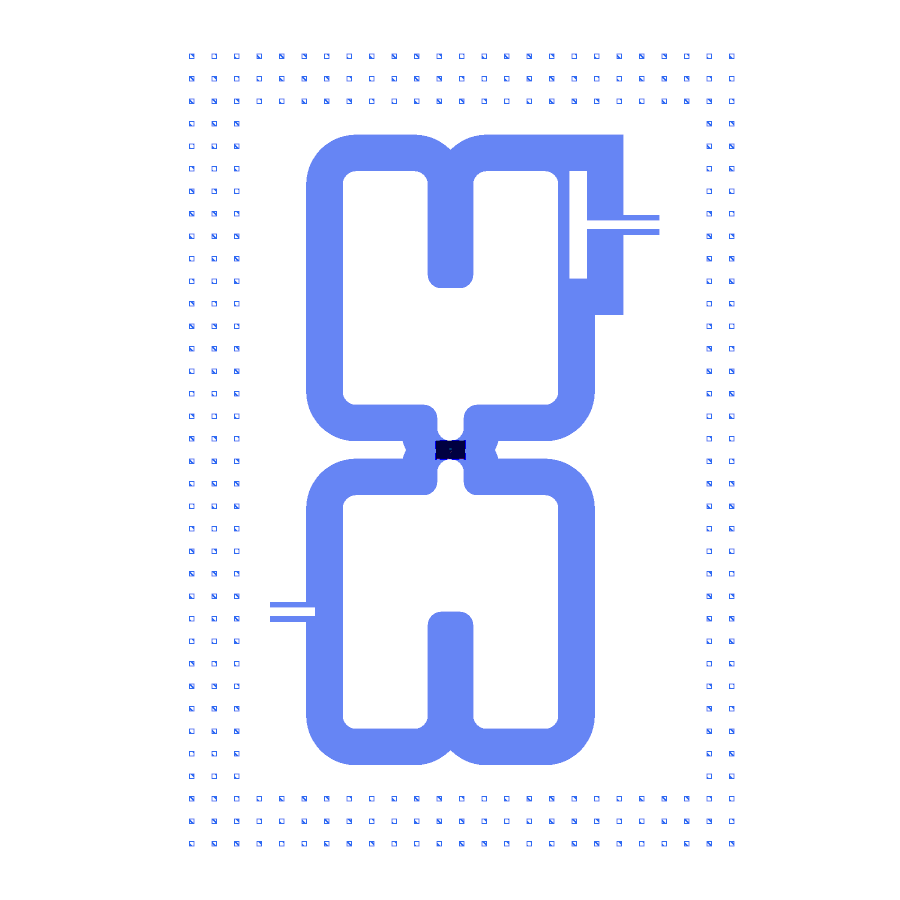

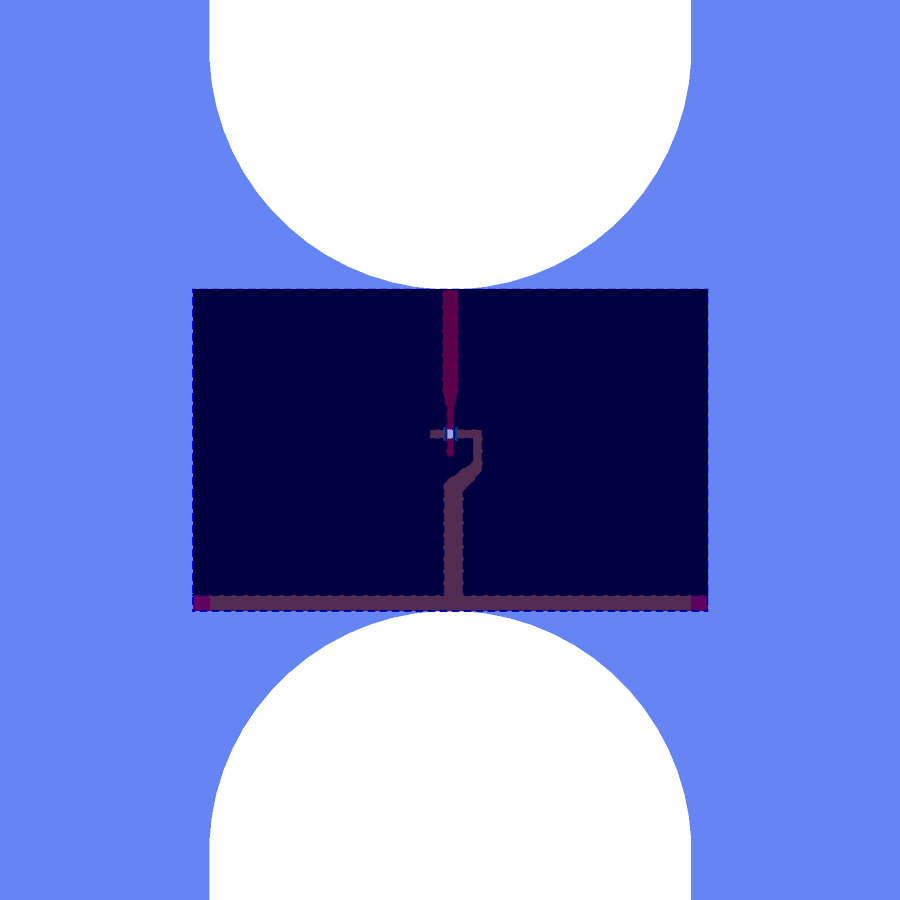

WindowsPath('examples/custom_component/img/qubit_junction.png')

In [3]:
params, junction = trilayer_junction("custom_qubit.ForkTransmon")
print(params, junction)
d0 = Designer("qc_fork_alone", box=(0, 0, 7500, 7500), chip={"name_chip": "QC1"}, live=False)
d0.add("Q1", "custom_qubit.ForkTransmon", at=(3750, 3750), junction=junction, **params)
snap(d0, "qubit_cell", box=(3750 - 500, 3750 - 450, 3750 + 500, 3750 + 450), width=420)
snap(d0, "qubit_junction", box=(3750 - 28, 3750 - 18, 3750 + 28, 3750 + 18), width=420)

## Size the junction for a target frequency, then place the qubit on a chip

The LOM gives the island capacitances, `size_junction` the L_J for the target frequency and the R_n it implies; the
PDK window (R_n 40-50 kOhm) is where a drawn junction is accepted without a DRC design warning. A bigger body adds
capacitance and lowers the frequency, so the body is the knob: a 300 x 300 µm body puts L_J inside the window.

In [4]:
d, fl = die("qc_fork_chip")
params, junction = trilayer_junction("custom_qubit.ForkTransmon")
q1 = d.add("Q1", "custom_qubit.ForkTransmon", at=(3750, 2300), body_w=300, body_len=300, junction=junction, **params)
lb = d.lom()
c = {n: b.value["estimate"] for n, b in lb.model.branches.items() if b.type == "C"}
# the two islands in series, the mutual capacitance between them, and the claw
c_sigma = c["C_Q1_1"] * c["C_Q1_2"] / (c["C_Q1_1"] + c["C_Q1_2"]) + c["C_Q1_12"] + c["Cg_Q1_claw"]
s = size_junction(F_Q, c_sigma, c_includes_junction=False)
print(f"C_sum ~ {c_sigma:.1f} fF + C_J -> L_J {s.lj_nH:.2f} nH, R_n {s.rn_kohm:.1f} kOhm (in window: {s.rn_in_window})")
params, junction = trilayer_junction("custom_qubit.ForkTransmon", lj_nH=s.lj_nH)
q1.set(junction=junction, **params)             # one change -> one rebuild
print("drawn junction:", junction, params)

C_sum ~ 98.6 fF + C_J -> L_J 6.96 nH, R_n 46.5 kOhm (in window: True)
drawn junction: {'Lj_nH': 7.015, 'Cj_fF': 14.4} {'junction_type': 'Quantcore Junction', 'junction_params': {'lj_nH': 6.962886757003742}}


## The readout resonator

`d.route(name, start, end)` works from any pin: the claw is `q1.claw`. The λ/4 resonator ends in a coupler along the
feedline (`fl.hanger`); the first length is the bare λ/4 for the target.

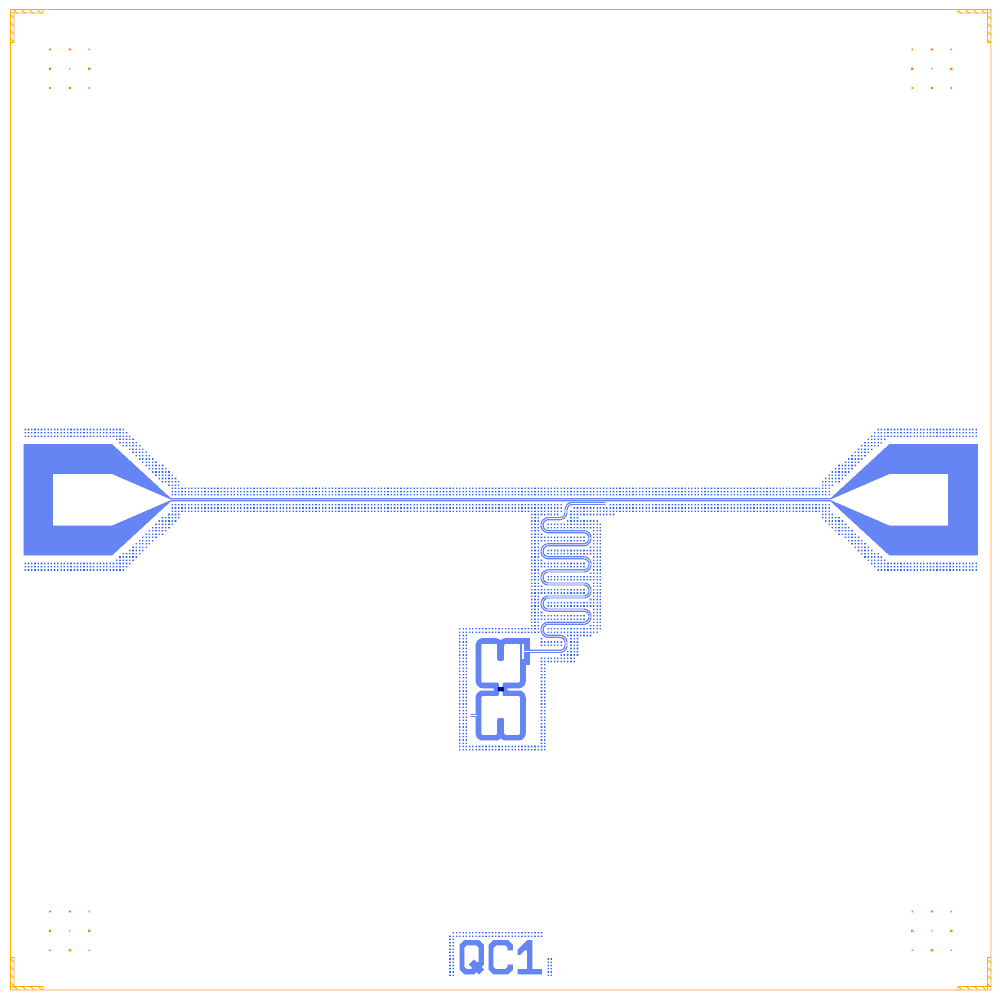

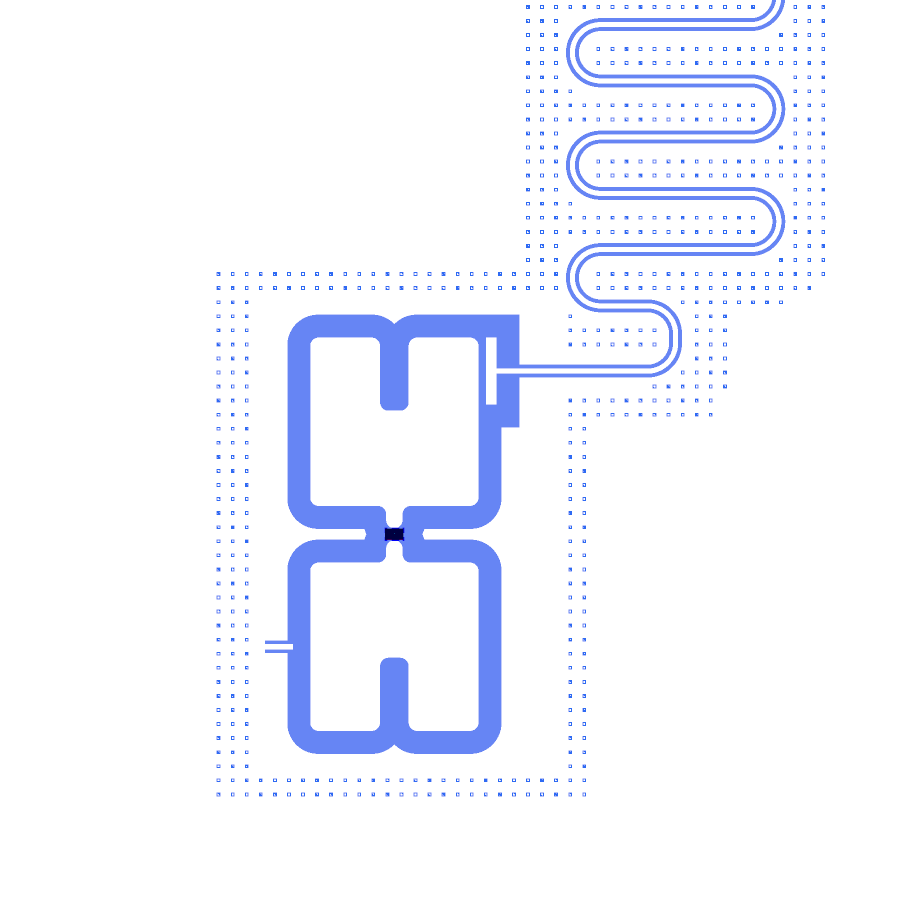

WindowsPath('examples/custom_component/img/qubit_chip_zoom.png')

In [5]:
vp = tl_resonator(4500, pdk.cpw_a, pdk.cpw_b)["vp_m_s"]
L_R1 = vp / (4 * F_R * 1e9) * 1e6
r1 = d.route("R1", q1.claw, fl.hanger(near=(4400, 3750), length=300, side="right"), meander=L_R1, r=50)
d.targets(Q1={"f_q_GHz": F_Q}, R1={"f_GHz": F_R})
snap(d, "qubit_chip", size=(1000, 1000), width=520)
snap(d, "qubit_chip_zoom", box=(3750 - 700, 2300 - 600, 3750 + 900, 2300 + 900), width=520)

## DRC

The DRC reads the pins: the claw is connected by the route, the `drive` pin is free and the `squid_a` / `squid_b`
refpoints (the junction ends, which the simulation export uses) are not routed. These three warnings are expected here.

In [6]:
rep = drc(d)

DRC: 0 errors, 3 warnings, 0 PDK design warnings
  warning dangling_port: Q1.drive is not connected (no route or snap)
  warning dangling_port: Q1.squid_a is not connected (no route or snap)
  warning dangling_port: Q1.squid_b is not connected (no route or snap)


## What the LOM says

The netlist is built from the component's own fragment: two islands, the junction between them, the claw as its own
node. The capacitances are rough formulas (marked as such in the netlist) until a Q3D C-matrix replaces them.

In [7]:
lb = d.lom()
C.show_netlist(lb)
res = C.simulate_lom(lb, d.design)
display(Markdown(C.modes_md(res)))
display(Markdown(C.summary_md(res, d.data["targets"])))

**5 nodes · 10 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `FL` | `FL`, `PAD_W.pad`, `PAD_E.pad` |
| `Q1.island1` | `Q1.island1` |
| `Q1.island2` | `Q1.island2` |
| `Q1.claw` | `Q1.claw` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_PAD_W` | R | `FL` – `gnd` | 50 Ω |
| `Port_PAD_E` | R | `FL` – `gnd` | 50 Ω |
| `C_Q1_1` | C | `Q1.island1` – `gnd` | 160 fF |
| `C_Q1_2` | C | `Q1.island2` – `gnd` | 160 fF |
| `C_Q1_12` | C | `Q1.island1` – `Q1.island2` | 12 fF |
| `Cg_Q1_claw` | C | `Q1.island2` – `Q1.claw` | 6.6 fF |
| `Cc_Q1_claw` | C | `Q1.claw` – `gnd` | 13 fF |
| `J_Q1` | JJ | `Q1.island1` – `Q1.island2` | Lj 7.01 nH, Cj 14.4 fF |
| `R1` | TLres | `Q1.claw` – `gnd` | lambda/4, 4501 µm, 7.000 GHz |
| `K_R1` | HANGER | `Q1.claw` – `FL` | κ 0.214 MHz (L 300 µm) |

**Unconnected ports:** none

**Builder notes:**

- Q1: rough capacitances (no calibration for the fork shape); run a C-matrix to replace

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q1 | qubit | 5.7796 | 0.000275 | 178.2 | J_Q1 1.00 |
| R1 | resonator | 6.7727 | 0.187 | 0.0 | R1 1.00 |

| parameter | LOM (QuTiP) | target |
|---|---|---|
| `Q1.f_q_GHz` | 5.5947 | 5.5 |
| `Q1.alpha_MHz` | -193.23 | – |
| `R1.chi_MHz` | -0.76295 | – |
| `R1.f_GHz` | 6.7722 | 7 |
| `R1.kappa_MHz` | 0.18693 | – |

The resonator sits below its target because the claw loads the λ/4. One rescale of the drawn length corrects it:
only the meander length changes, the layout, the DRC and every value follow.

In [8]:
res1 = res
length = L_R1
for step in range(1, 4):
    f_r = res1.params["R1.f_GHz"]
    if abs(f_r / F_R - 1) < 0.003:
        break
    length *= f_r / F_R
    r1.set(meander=length)
    res1 = C.simulate_lom(d.lom(), d.design)
    print(f"step {step}: R1 {length:.0f} um -> f_r {res1.params['R1.f_GHz']:.4f} GHz")
keys = ["Q1.f_q_GHz", "Q1.alpha_MHz", "R1.f_GHz", "R1.chi_MHz", "R1.kappa_MHz"]
display(Markdown("| quantity | value |\n|---|---|\n" + "\n".join(f"| `{k}` | {res1.params[k]:.4g} |" for k in keys)))
FORK_LOM = {k: res1.params[k] for k in keys} | {"L_J_nH": s.lj_nH, "R_n_kOhm": s.rn_kohm, "C_sum_fF": c_sigma}
FORK_LOM

step 1: R1 4355 um -> f_r 6.9921 GHz


| quantity | value |
|---|---|
| `Q1.f_q_GHz` | 5.595 |
| `Q1.alpha_MHz` | -193.4 |
| `R1.f_GHz` | 6.992 |
| `R1.chi_MHz` | -0.6074 |
| `R1.kappa_MHz` | 0.2056 |

{'Q1.f_q_GHz': 5.594912822214787,
 'Q1.alpha_MHz': -193.39052462215633,
 'R1.f_GHz': 6.992117178163709,
 'R1.chi_MHz': -0.607384049187587,
 'R1.kappa_MHz': 0.20560579056990477,
 'L_J_nH': 6.962886757003742,
 'R_n_kOhm': 46.526616723460904,
 'C_sum_fF': 98.6}

# 2 · The spiralmon, from a drawn shape

An oblique spiral island with a qubit junction to ground. The shape is not a parametric library cell: it is a
drawing. A drawing becomes a component with three things: **polygons**, **named pins** and a **junction location**.
`freeform.py` holds the helper (`FreeformComponent`, `Pin`, `read_polygons`, `component_from_polygons`);
`spiralmon.py` generates the spiral polygons.

## The polygons

{'hull_area_um2': 28903.3, 'wire_length_um': 955.2, 'claw_length_um': 146.7}
pin: Pin(name='claw', x=94.16885807623794, y=-141.73843786845075, angle=-57.248742315326886, a=10.0, b=6.0, tail=70.0)
junction line: [(-66.3, 96.9), (-79.9, 117.8)]


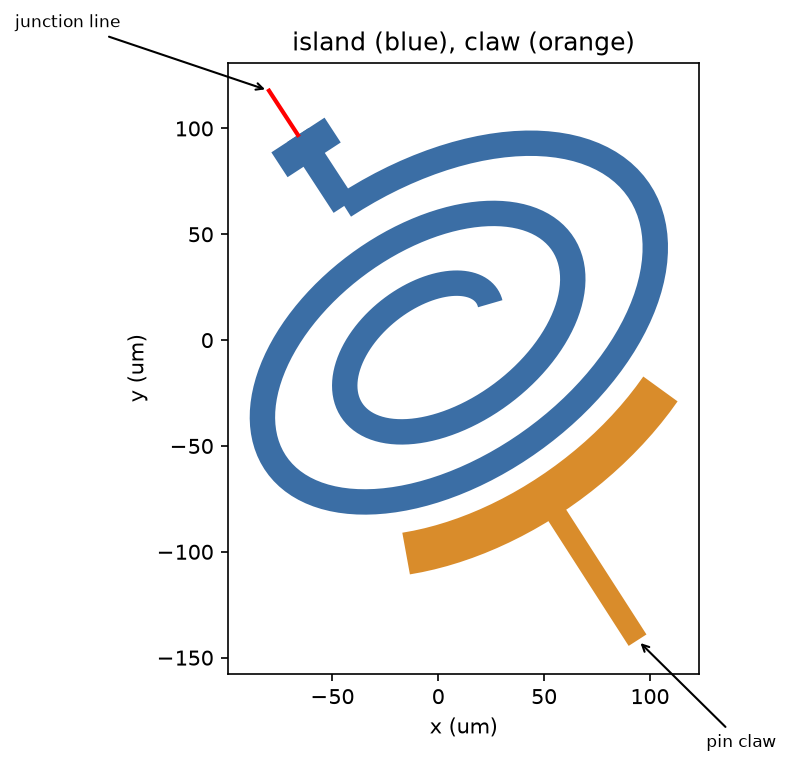

In [9]:
import matplotlib.pyplot as plt
import spiralmon, freeform

shape = spiralmon.spiral_shapes()
print({k: round(v, 1) for k, v in shape["geometry"].items() if isinstance(v, float)})
print("pin:", shape["pins"][0])
print("junction line:", [tuple(round(v, 1) for v in pt) for pt in shape["junction"]])

fig, ax = plt.subplots(figsize=(5.2, 5.2), dpi=150)
for poly in shape["island"]:
    ax.fill(*zip(*[(p.x, p.y) for p in poly.each_point_hull()]), color="#3b6ea5", lw=0)
for poly in shape["claw"]:
    ax.fill(*zip(*[(p.x, p.y) for p in poly.each_point_hull()]), color="#d98c2b", lw=0)
pin = shape["pins"][0]
ux, uy = pin.direction()
ax.annotate("pin claw", (pin.x, pin.y), (pin.x + 60 * ux, pin.y + 60 * uy), arrowprops={"arrowstyle": "->"}, fontsize=8)
(xa, ya), (xb, yb) = shape["junction"]
ax.plot([xa, xb], [ya, yb], "r-", lw=2)
ax.annotate("junction line", (xb, yb), (xb - 120, yb + 30), arrowprops={"arrowstyle": "->"}, fontsize=8)
ax.set_aspect("equal"); ax.set_xlabel("x (um)"); ax.set_ylabel("y (um)"); ax.set_title("island (blue), claw (orange)")
fig.tight_layout()
fig.savefig(IMG / "spiralmon_polygons.png")
plt.show()

## From a drawing in KLayout

Someone could have drawn this in KLayout and saved it. `read_polygons(path, layer)` reads the polygons of one layer of an
`.oas` / `.gds` cell. Here the file is written from the Python shape (a stand-in for the drawing: island on layer 10/0,
claw on 11/0) and read back. The pin position and the junction line are not in the file: you read them off the drawing
with the ruler (coordinates in µm) and type them in.

In [10]:
path = spiralmon.drawn_spiralmon_file()
island = freeform.read_polygons(path, spiralmon.LAYER_ISLAND)
claw = freeform.read_polygons(path, spiralmon.LAYER_CLAW)
print(path.name, "->", len(island), "island polygon(s),", len(claw), "claw polygon(s); area", round(sum(p.area() for p in island)), "um2")

spiralmon_drawn.oas -> 1 island polygon(s), 1 claw polygon(s); area 11679 um2


## The component class

`Spiralmon` (parametric, polygons from the parameters) and `DrawnSpiralmon` (a fixed shape from the file, made by
`component_from_polygons`) are both `FreeformComponent`s. They draw the same etched pattern: the XOR is empty.

In [11]:
from kqcircuits.defaults import default_layers
from kqcircuits.pya_resolver import pya
from quantcore_circuits.layouts.registry import create_cell

ly = pya.Layout()
a = create_cell(ly, spiralmon.Spiralmon)
b = create_cell(ly, spiralmon.DrawnSpiralmon)
for layer in ("1t1_base_metal_gap_wo_grid", "1t1_SIS_junction", "1t1_SIS_junction_2"):
    ra = pya.Region(a.begin_shapes_rec(ly.layer(default_layers[layer]))).merged()
    rb = pya.Region(b.begin_shapes_rec(ly.layer(default_layers[layer]))).merged()
    xor = (ra ^ rb).sized(-2).area() * 1e-6
    print(f"{layer:30s} parametric {ra.area() * 1e-6:10.1f} um2   drawn {rb.area() * 1e-6:10.1f} um2   XOR {xor:.1f} um2")

1t1_base_metal_gap_wo_grid     parametric    36849.2 um2   drawn    36849.2 um2   XOR 0.0 um2
1t1_SIS_junction               parametric      788.4 um2   drawn      788.4 um2   XOR 0.0 um2
1t1_SIS_junction_2             parametric      751.2 um2   drawn      751.2 um2   XOR 0.0 um2


## Place it on a chip with a readout

The claw pin points obliquely (the spiral is tilted); `rot = 35 - pin angle` turns the whole cell so the claw pin looks up and to the right (35 deg) toward the feedline, and
`d.route` follows the pin direction. The junction is the PDK
trilayer junction, sized for the target.

In [12]:
d2, fl2 = die("qc_spiralmon_chip")
params, junction = trilayer_junction("spiralmon.Spiralmon")      # the PDK nominal junction first
q2 = d2.add("Q1", "spiralmon.Spiralmon", at=(3300, 2250), rot=35 - shape["pins"][0].angle, junction=junction, **params)


def csum(design_lom):
    c = {n: bb.value["estimate"] for n, bb in design_lom.model.branches.items() if bb.type == "C"}
    return c["C_Q1"] + c["Cg_Q1_claw"]


s2 = size_junction(F_Q, csum(d2.lom()), c_includes_junction=False)
print(f"C_sum ~ {csum(d2.lom()):.1f} fF + C_J -> L_J {s2.lj_nH:.2f} nH, R_n {s2.rn_kohm:.1f} kOhm (in window: {s2.rn_in_window})")

C_sum ~ 81.0 fF + C_J -> L_J 8.35 nH, R_n 55.8 kOhm (in window: False)


The spiral island alone is small (81 fF in all): the junction for the target frequency would need R_n above the PDK
window. The spiral can
be made bigger: three turns and a wider pitch. Then the junction is sized for the target.

C_sum ~ 115.0 fF + C_J -> L_J 6.03 nH, R_n 40.3 kOhm (in window: True)


drawn junction: {'Lj_nH': 6.0129, 'Cj_fF': 16.8}


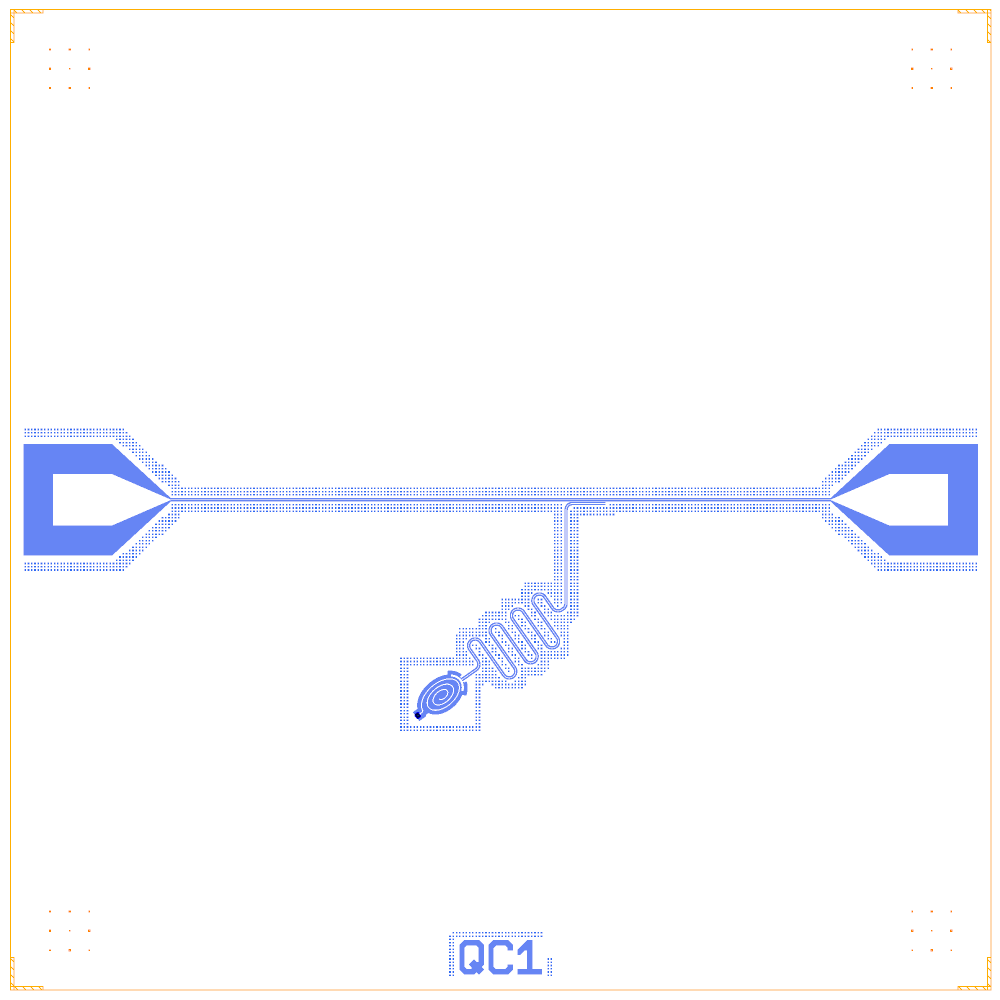

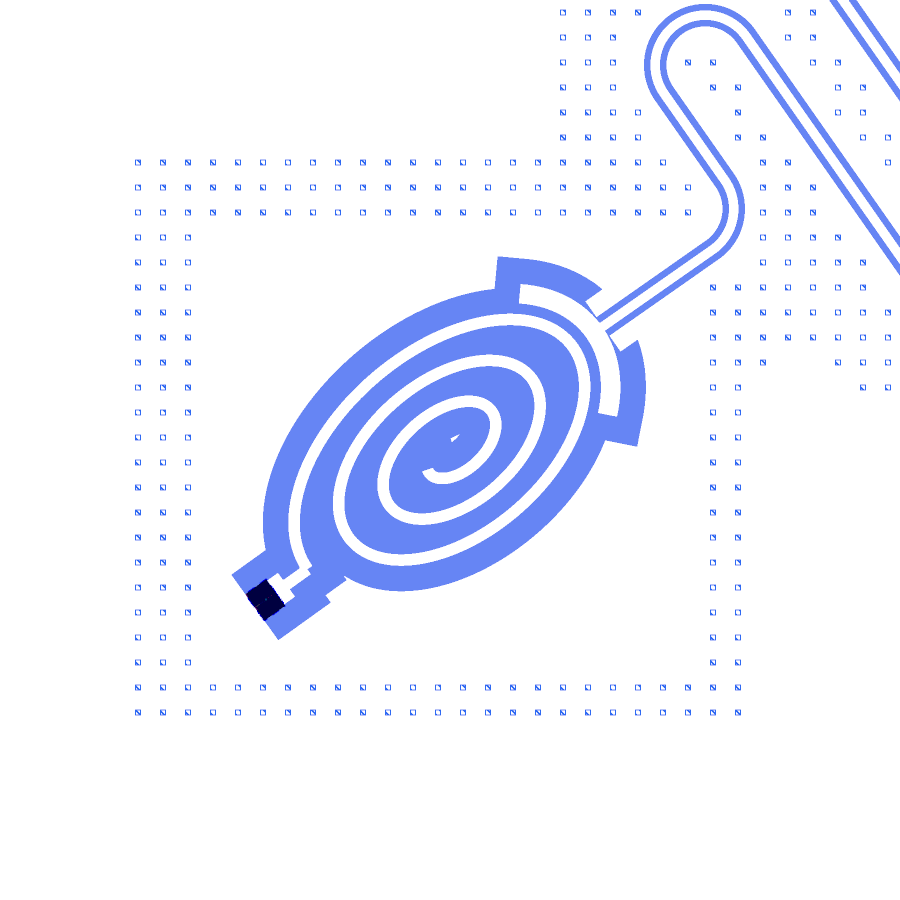

WindowsPath('examples/custom_component/img/spiralmon_zoom.png')

In [13]:
pin_angle = spiralmon.spiral_shapes(turns=3.0, pitch=52.0)["pins"][0].angle   # the claw moves with the turns
q2.set(turns=3.0, pitch=52.0, rot=35 - pin_angle)
c_sigma2 = csum(d2.lom())
s2 = size_junction(F_Q, c_sigma2, c_includes_junction=False)
print(f"C_sum ~ {c_sigma2:.1f} fF + C_J -> L_J {s2.lj_nH:.2f} nH, R_n {s2.rn_kohm:.1f} kOhm (in window: {s2.rn_in_window})")
params, junction = trilayer_junction("spiralmon.Spiralmon", lj_nH=s2.lj_nH)
q2.set(junction=junction, **params)
print("drawn junction:", junction)
r2 = d2.route("R1", q2.claw, fl2.hanger(near=(4400, 3750), length=300, side="right"), meander=L_R1, r=50)
d2.targets(Q1={"f_q_GHz": F_Q}, R1={"f_GHz": F_R})
snap(d2, "spiralmon_chip", size=(1000, 1000), width=520)
snap(d2, "spiralmon_zoom", box=(3300 - 450, 2250 - 400, 3300 + 450, 2250 + 400), width=440)

## DRC and the LOM

As for the fork transmon, `squid_a` / `squid_b` (the junction ends) are not routed and give two warnings.

In [14]:
rep2 = drc(d2)

DRC: 0 errors, 2 warnings, 0 PDK design warnings
  warning dangling_port: Q1.squid_a is not connected (no route or snap)
  warning dangling_port: Q1.squid_b is not connected (no route or snap)


In [15]:
lb2 = d2.lom()
C.show_netlist(lb2)
res2 = C.simulate_lom(lb2, d2.design)
display(Markdown(C.modes_md(res2)))
display(Markdown(C.summary_md(res2, d2.data["targets"])))

**4 nodes · 8 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `FL` | `FL`, `PAD_W.pad`, `PAD_E.pad` |
| `Q1` | `Q1.island` |
| `Q1.claw` | `Q1.claw` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_PAD_W` | R | `FL` – `gnd` | 50 Ω |
| `Port_PAD_E` | R | `FL` – `gnd` | 50 Ω |
| `C_Q1` | C | `Q1` – `gnd` | 100 fF |
| `Cg_Q1_claw` | C | `Q1` – `Q1.claw` | 15 fF |
| `Cc_Q1_claw` | C | `Q1.claw` – `gnd` | 30 fF |
| `J_Q1` | JJ | `Q1` – `gnd` | Lj 6.01 nH, Cj 16.8 fF |
| `R1` | TLres | `Q1.claw` – `gnd` | lambda/4, 4501 µm, 7.000 GHz |
| `K_R1` | HANGER | `Q1.claw` – `FL` | κ 0.214 MHz (L 300 µm) |

**Unconnected ports:** none

**Builder notes:**

- Q1: the spiral's own inductance (about 1 nH per mm of wire, 1.7 mm here) is not in the model; capacitances are rough, run a C-matrix to replace them

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q1 | qubit | 5.6171 | 0.00417 | 131.8 | J_Q1 0.95, R1 0.05 |
| R1 | resonator | 6.5902 | 0.16 | 0.4 | R1 0.95, J_Q1 0.05 |

| parameter | LOM (QuTiP) | target |
|---|---|---|
| `Q1.f_q_GHz` | 5.4727 | 5.5 |
| `Q1.alpha_MHz` | -146 | – |
| `R1.chi_MHz` | -11.018 | – |
| `R1.f_GHz` | 6.583 | 7 |
| `R1.kappa_MHz` | 0.16016 | – |

In [16]:
length = L_R1
for step in range(1, 4):
    f_r = res2.params["R1.f_GHz"]
    if abs(f_r / F_R - 1) < 0.003:
        break
    length *= f_r / F_R
    r2.set(meander=length)
    res2 = C.simulate_lom(d2.lom(), d2.design)
    print(f"step {step}: R1 {length:.0f} um -> f_r {res2.params['R1.f_GHz']:.4f} GHz")
display(Markdown("| quantity | value |\n|---|---|\n" + "\n".join(f"| `{k}` | {res2.params[k]:.4g} |" for k in keys)))
SPIRAL_LOM = {k: res2.params[k] for k in keys} | {"L_J_nH": s2.lj_nH, "R_n_kOhm": s2.rn_kohm, "C_sum_fF": c_sigma2}
SPIRAL_LOM

step 1: R1 4233 um -> f_r 6.9633 GHz
step 2: R1 4211 um -> f_r 6.9970 GHz


| quantity | value |
|---|---|
| `Q1.f_q_GHz` | 5.48 |
| `Q1.alpha_MHz` | -149.9 |
| `R1.f_GHz` | 6.997 |
| `R1.chi_MHz` | -7.255 |
| `R1.kappa_MHz` | 0.195 |

{'Q1.f_q_GHz': 5.480378459487764,
 'Q1.alpha_MHz': -149.93086941619538,
 'R1.f_GHz': 6.996976043103719,
 'R1.chi_MHz': -7.2551899690740385,
 'R1.kappa_MHz': 0.19498477446299992,
 'L_J_nH': 6.02883342796982,
 'R_n_kOhm': 40.285190895944666,
 'C_sum_fF': 115.0}

## What next

Both components stay simple on purpose. A C-matrix of each cell (`q3d_cmatrix`, one job per cell, see the FEM part of
the tutorials) replaces the rough capacitances by FEM values by net name (`Q1.island1`, `Q1.island2`, `Q1.claw` for the fork
transmon; `Q1.island`, `Q1.claw` for the spiralmon). Solving needs the simulation PC and is not run here.